# 00 · Pipeline: la base operacional «retail»

## Antes de empezar: qué vamos a construir en estos cinco cuadernos

**El problema.** Una tienda online del Reino Unido vende regalos y artículos de decoración. Quiere saber, cada cierto tiempo,
**qué clientes van a volver a comprar** para dedicar sus campañas (descuentos, correos, llamadas) a quienes tienen riesgo de irse.

**La pregunta de negocio**, escrita de forma que un modelo pueda responderla:

> Dado un cliente y una **fecha de corte**, ¿volverá a comprar en los **90 días siguientes**?

Es una **clasificación binaria**: la respuesta es sí (`y = 1`) o no (`y = 0`). El modelo no contesta con un sí o un no, sino con una
**probabilidad** (por ejemplo, 0,82), que sirve para ordenar a los clientes de más a menos probable.

**El producto final** es un modelo entrenado, con sus métricas y sus metadatos, listo para que en S2 una **API** lo use para responder
«¿qué probabilidad tiene el cliente 12347 de volver?». Para llegar ahí recorremos todo el camino del dato:

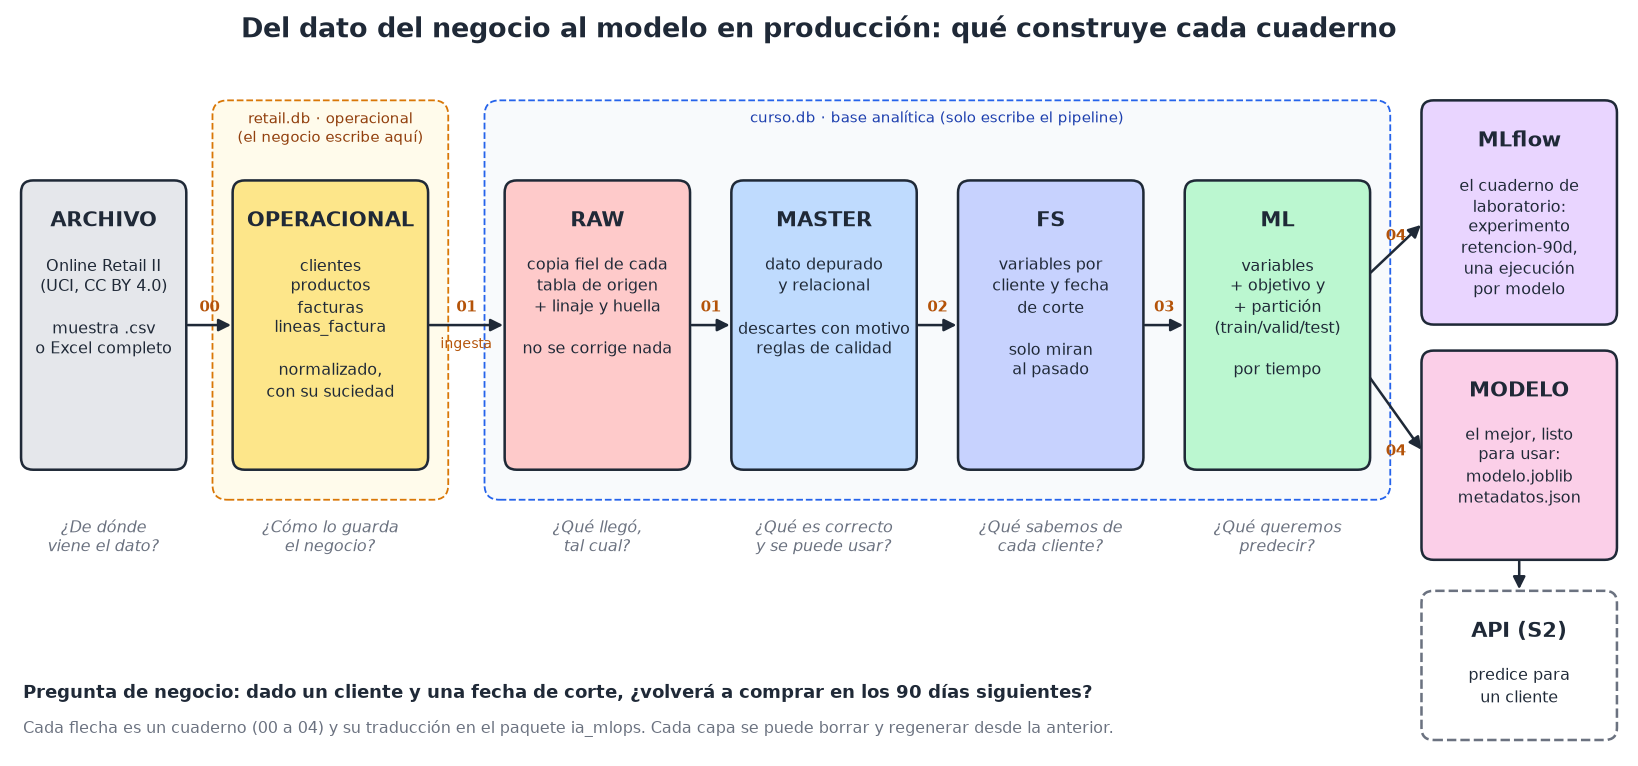

**Cómo leer el diagrama.** Cada caja es un lugar donde vive el dato y cada flecha es un **cuaderno** que lo transforma.
Hay dos bases de datos distintas, y es a propósito:
- `retail.db` (amarilla) simula el **sistema operacional** de la tienda: donde se registra cada venta. La crea este cuaderno.
- `curso.db` (azul) es la **base analítica**: donde el pipeline guarda, por capas, todo lo que necesita para entrenar.

El pipeline analítico **lee** del operacional, pero **nunca escribe** en él.

## El mapa de los cuadernos

| Cuaderno | Objetivo | Lee de | Escribe en | Pregunta que responde |
|---|---|---|---|---|
| **00 · operacional** | Simular el sistema de ventas | archivo de UCI | `retail.db`: `clientes`, `productos`, `facturas`, `lineas_factura` | ¿Cómo guarda el negocio sus ventas? |
| **01 · RAW → MASTER** | Ingerir el operacional sin tocarlo (RAW) y depurarlo (MASTER) | `retail.db` | `curso.db`: `raw_*`, `master_*` | ¿Qué llegó? ¿Qué es correcto? |
| **02 · MASTER → FS** | Calcular variables de cada cliente en cada fecha de corte | `master_*` | `fs_cliente_corte`, `fs_catalogo` | ¿Qué sabemos de cada cliente *hasta ese día*? |
| **03 · FS → ML** | Añadir el objetivo `y` y repartir en train / valid / test | `fs_*`, `master_*` | `ml_dataset`, `ml_particiones` | ¿Qué queremos predecir y con qué datos se evalúa? |
| **04 · entrenamiento** | Entrenar, comparar y registrar modelos en MLflow; guardar el mejor | `ml_dataset` | `models/`, `reports/`, MLflow | ¿Qué modelo funciona mejor y por qué? |

Cada cuaderno **empieza leyendo la capa anterior y termina dejando la suya construida y comprobada**. Por eso se ejecutan **en orden**.

### Glosario: las ideas que usaremos en todos los cuadernos
| Término | Qué significa aquí |
|---|---|
| **Pipeline** | Secuencia de pasos automáticos que transforma el dato desde su origen hasta el resultado. Aquí, cada cuaderno es un tramo del pipeline. |
| **Capa** | Conjunto de tablas con una responsabilidad clara (RAW, MASTER, FS, ML). Cada capa se puede **borrar y regenerar** desde la anterior. |
| **Sistema operacional (OLTP)** | La base con la que funciona el negocio día a día: registra ventas, clientes, productos. Optimizada para escribir muchas operaciones pequeñas. |
| **Base analítica** | La base donde se analiza y se entrena. Se llena copiando del operacional, nunca al revés. |
| **Ingesta** | Copiar los datos del sistema de origen a la capa RAW. |
| **Linaje** | Poder decir de dónde viene cada registro (qué tabla, qué fila, qué carga). |
| **Huella (sha256)** | Un «DNI» de 64 caracteres calculado a partir del contenido. Si cambia un solo byte, cambia la huella. Sirve para saber si dos datos son idénticos. |
| **Fecha de corte** | El «hoy» de una foto: todo lo anterior se conoce, todo lo posterior es futuro. |
| **Fuga de información** | Que el modelo vea, al entrenar, datos que en la realidad aún no existirían. Da métricas buenísimas que luego no se cumplen. |
| **Experimento (MLflow)** | Una carpeta lógica donde se guardan todas las **ejecuciones** de entrenamiento de un mismo problema, para compararlas. |

### Cómo trabajar con estos cuadernos
1. En VS Code elige el kernel **env-ia-mlops** (arriba a la derecha).
2. Ejecuta las celdas **de arriba abajo** (o *Ejecutar todo*). Si cambias algo, vuelve a ejecutar desde el principio.
3. La segunda celda de cada cuaderno es la de **parámetros**: es lo único que se cambia para ejecutar con otros datos.
4. La lógica de datos está en archivos **SQL** de la carpeta `sql/`. El cuaderno los ejecuta: ábrelos y léelos, son parte del curso.
5. Todo lo que hacen los cuadernos lo hace también el paquete **`ia_mlops`**, en **cuatro pipelines independientes e idempotentes**: `pipeline_ingesta_raw` (cuaderno 01, RAW), `pipeline_ingesta_master` (cuaderno 01, MASTER), `pipeline_ml` (cuadernos 02 y 03) y `pipeline_train` (cuaderno 04). Se lanzan con `python -m ia_mlops.<pipeline>` o los cuatro seguidos con `python -m ia_mlops.pipeline`. Las pruebas exigen que cuadernos y paquete den **exactamente** el mismo resultado.
6. Desde la terminal, un cuaderno se ejecuta con `papermill`, por ejemplo: `papermill notebooks/00_pipeline_operacional.ipynb salida.ipynb -p FUENTE muestra`.

## Este cuaderno: objetivo

**Objetivo:** construir `data/external/retail.db`, una base de datos que **simula el sistema de ventas** de la tienda.

**¿Por qué simularlo?** En una empresa el dato no llega en un CSV: vive en los **sistemas operacionales**. El dataset público de UCI
es una *exportación plana* de ese sistema (una fila por línea de factura, con el cliente y el país repetidos en cada línea).
Para practicar el flujo real, hacemos el camino inverso: a partir del archivo reconstruimos un modelo **normalizado**, como el que tendría la tienda,
y a partir de ahí el pipeline trabaja como lo haría en producción: ingiriendo desde una base de datos.

| | Base operacional (`retail.db`) | Base analítica (`curso.db`) |
|---|---|---|
| Para qué sirve | Registrar cada venta en el momento | Analizar y entrenar modelos |
| Cómo se organiza | Normalizada: cada dato se guarda **una vez** | Por capas: RAW → MASTER → FS → ML |
| Quién escribe | El negocio (aquí, este cuaderno) | Solo el pipeline |
| Si se rompe… | La tienda no puede vender | Se regenera desde el operacional |

**La simulación no limpia nada.** Líneas repetidas, descripciones vacías, ventas sin cliente, cancelaciones y códigos que no son productos
(gastos de envío, comisiones…) se quedan como están: un sistema real también los tiene, y tratarlos es trabajo de MASTER (cuaderno 01).

**Entra:** el archivo de UCI (la muestra CSV del repositorio o el Excel completo). **Sale:** `retail.db` con 4 tablas de negocio y 1 de control.

In [1]:
# Parámetros. papermill puede sobrescribirlos:  papermill 00_pipeline_operacional.ipynb salida.ipynb -p FUENTE completo
# FUENTE: 'muestra' (CSV del repositorio, segundos) o 'completo' (Excel original de UCI, 1,07 millones de filas)
FUENTE = 'muestra'
# RUTA_OPERACIONAL: None usa data/external/retail.db, o la variable de entorno CURSO_DB_OPERACIONAL
RUTA_OPERACIONAL = None

### Preparación: rutas y conexión
La celda siguiente localiza la carpeta del proyecto (la que contiene `sql/` y `pyproject.toml`), decide dónde estará la base y abre una **conexión**
SQLite. SQLite guarda toda la base en **un solo archivo**: si no existe, lo crea.
`PRAGMA foreign_keys = ON` activa la comprobación de **claves foráneas**, que SQLite trae apagada por defecto.

In [2]:
import os, sqlite3
from pathlib import Path

import pandas as pd

pd.set_option('display.width', 150, 'display.max_columns', 30)

# Carpeta del proyecto: la que contiene «sql» y «pyproject.toml».
RAIZ = Path.cwd().resolve()
while not ((RAIZ / 'sql').exists() and (RAIZ / 'pyproject.toml').exists()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
SQL = RAIZ / 'sql'
DB_OPERACIONAL = Path(RUTA_OPERACIONAL or os.environ.get('CURSO_DB_OPERACIONAL') or RAIZ / 'data' / 'external' / 'retail.db')
DB_OPERACIONAL.parent.mkdir(parents=True, exist_ok=True)

con = sqlite3.connect(DB_OPERACIONAL)
con.execute('PRAGMA foreign_keys = ON')


def ejecutar_script(archivo):
    """Ejecuta un archivo .sql de la carpeta sql/ (puede tener varias sentencias)."""
    con.executescript((SQL / archivo).read_text(encoding='utf-8'))
    con.commit()


def escalar(consulta, parametros=None):
    """Devuelve un único valor: la primera columna de la primera fila de la consulta."""
    fila = con.execute(consulta, parametros or {}).fetchone()
    return None if fila is None else fila[0]


print('Proyecto:', RAIZ)
print('Base operacional:', DB_OPERACIONAL)

Proyecto: C:\bk\HC-Cursos\curso-ml-ia-desarrollo-produccion\04-Proyecto-Base
Base operacional: C:\bk\HC-Cursos\curso-ml-ia-desarrollo-produccion\04-Proyecto-Base\data\external\retail.db


## 1. Leer el archivo de origen
Cada fila del archivo es una **línea de factura**: un producto vendido (o devuelto) dentro de una factura. Sus 8 columnas:

| Columna | Significado | Ejemplo |
|---|---|---|
| `Invoice` | Número de factura. Si empieza por `C`, es una **cancelación** | `489434`, `C489449` |
| `StockCode` | Código del producto | `85048`, `POST` (envío) |
| `Description` | Descripción del producto | `15CM CHRISTMAS GLASS BALL 20 LIGHTS` |
| `Quantity` | Unidades (negativas en cancelaciones) | `12` |
| `InvoiceDate` | Fecha y hora | `2009-12-01 07:45:00` |
| `Price` | Precio unitario en libras | `6.95` |
| `Customer ID` | Identificador del cliente (puede faltar) | `13085.0` |
| `Country` | País del cliente | `United Kingdom` |

**Solo se armonizan los tipos, no los valores.** El Excel guarda algunos números de factura como `489434.0` y el cliente como decimal;
aquí se pasan a texto (`'489434'`) y a entero (`13085`). Un espacio de más, una mayúscula o una descripción vacía **se conservan**.
`linea_id` es la posición de la fila en el archivo: será la clave de la línea y permitirá volver siempre al original.

In [3]:
import hashlib, math
from datetime import datetime

FUENTES = {
    'muestra': RAIZ / 'data' / 'raw' / 'muestra_online_retail_ii.csv',
    'completo': RAIZ / 'data' / 'raw' / 'online_retail_ii' / 'online_retail_II.xlsx',
}
COLUMNAS = ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


def sha256_archivo(ruta):
    """Huella sha256 del archivo: si cambia un solo byte, cambia la huella."""
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        for bloque in iter(lambda: f.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()


def _nulo(v):
    return v is None or v is pd.NaT or (isinstance(v, float) and math.isnan(v))


def _texto(v):
    """Conserva el valor como texto; los nulos siguen siendo nulos; 489434.0 se guarda como '489434'."""
    if _nulo(v):
        return None
    if isinstance(v, float) and v.is_integer():
        return str(int(v))
    return str(v)


def _numero(v, entero=False):
    if _nulo(v):
        return None
    return int(float(v)) if entero else float(v)


def _fecha_iso(v):
    """Fecha en formato ISO 8601 (AAAA-MM-DD HH:MM:SS): así se ordena bien también como texto."""
    if _nulo(v):
        return None
    return v if isinstance(v, str) else pd.Timestamp(v).strftime('%Y-%m-%d %H:%M:%S')

In [4]:
ruta = FUENTES[FUENTE]
if not ruta.exists():
    raise FileNotFoundError(f'No existe {ruta}. Para la fuente completa ejecuta antes:  python -m ia_mlops.dataset descargar')

# dtype=object: pandas no adivina tipos; leemos el valor tal cual y lo convertimos nosotros, de forma explícita.
if ruta.suffix.lower() == '.csv':
    hojas = [(ruta.name, pd.read_csv(ruta, dtype=object, keep_default_na=False, na_values=['']))]
else:
    hojas = list(pd.read_excel(ruta, sheet_name=None, dtype=object).items())   # el Excel trae dos hojas (una por año)

lineas = []   # (linea_id, factura_id, codigo_producto, descripcion, cantidad, registrada_en, precio_unitario, cliente_id, pais)
for nombre, df in hojas:
    for r in df[COLUMNAS].itertuples(index=False, name=None):
        lineas.append((len(lineas) + 1, _texto(r[0]), _texto(r[1]), _texto(r[2]), _numero(r[3], entero=True),
                       _fecha_iso(r[4]), _numero(r[5]), _numero(r[6], entero=True), _texto(r[7])))
    print(f'hoja {nombre!r}: {len(df):,} filas')
print(f'{len(lineas):,} líneas leídas de {ruta.name}')

hoja 'muestra_online_retail_ii.csv': 23,070 filas
23,070 líneas leídas de muestra_online_retail_ii.csv


## 2. ¿Se puede normalizar sin perder información?
**Normalizar** es organizar las tablas para que **cada dato se guarde una sola vez**, en la tabla a la que pertenece.
En el archivo plano, el cliente y el país de una factura se repiten en **cada una de sus líneas**: si la factura tiene 20 líneas, el país está escrito 20 veces.
Eso tiene dos problemas: ocupa más y, sobre todo, permite **contradicciones** (una línea dice «France» y otra «Germany» para la misma factura).

La normalización separa:
- lo que es **de la factura** (cliente, país, fecha de emisión) → tabla `facturas`, una fila por factura;
- lo que es **de cada línea** (producto, cantidad, precio) → tabla `lineas_factura`, una fila por línea;
- lo que es **del cliente** y **del producto** → `clientes` y `productos`.

**La condición para no perder nada:** cada factura debe tener **un único** cliente y un único país. Si tuviera dos, al guardarlos una sola vez
perderíamos uno. Por eso, **antes** de normalizar, lo medimos. La fecha es distinta: algunas facturas tienen líneas registradas en minutos diferentes,
así que **cada línea guarda su propia fecha** (`registrada_en`) y la factura guarda la de su primera línea.

Primero se crean las tablas vacías (`sql/operacional/01_crear_operacional.sql`) y se cargan las líneas en una tabla **temporal**
(`temp.tmp_origen`): existe solo mientras dura la conexión y no queda en la base.

In [5]:
ejecutar_script('operacional/01_crear_operacional.sql')
con.execute('CREATE TEMP TABLE tmp_origen (linea_id INTEGER, factura_id TEXT, codigo_producto TEXT, descripcion TEXT, '
            'cantidad INTEGER, registrada_en TEXT, precio_unitario REAL, cliente_id INTEGER, pais TEXT)')
con.executemany('INSERT INTO temp.tmp_origen VALUES (?,?,?,?,?,?,?,?,?)', lineas)

# COUNT(DISTINCT IFNULL(cliente_id, -1)): cuenta el «sin cliente» (nulo) como un valor más, para detectar facturas mezcladas.
comprobaciones = {
    'facturas con varios clientes': escalar('SELECT COUNT(*) FROM (SELECT factura_id FROM temp.tmp_origen GROUP BY factura_id '
                                            'HAVING COUNT(DISTINCT IFNULL(cliente_id, -1)) > 1)'),
    'facturas con varios paises': escalar('SELECT COUNT(*) FROM (SELECT factura_id FROM temp.tmp_origen GROUP BY factura_id '
                                          'HAVING COUNT(DISTINCT pais) > 1)'),
    'facturas con varias fechas (se guardan en la línea)': escalar('SELECT COUNT(*) FROM (SELECT factura_id FROM temp.tmp_origen '
                                                                   'GROUP BY factura_id HAVING COUNT(DISTINCT registrada_en) > 1)'),
}
assert comprobaciones['facturas con varios clientes'] == 0 and comprobaciones['facturas con varios paises'] == 0, comprobaciones
pd.Series(comprobaciones, name='facturas')

facturas con varios clientes                           0
facturas con varios paises                             0
facturas con varias fechas (se guardan en la línea)    1
Name: facturas, dtype: int64

## 3. Derivar las tablas operacionales
`sql/operacional/01_crear_operacional.sql` define el modelo con sus **claves** y **restricciones**; `02_poblar_operacional.sql` lo llena desde `tmp_origen`.
**Ábrelos y léelos**: son SQL de verdad. Cuatro tablas de negocio, más `origen_simulacion`, que solo registra de qué archivo sale la simulación.

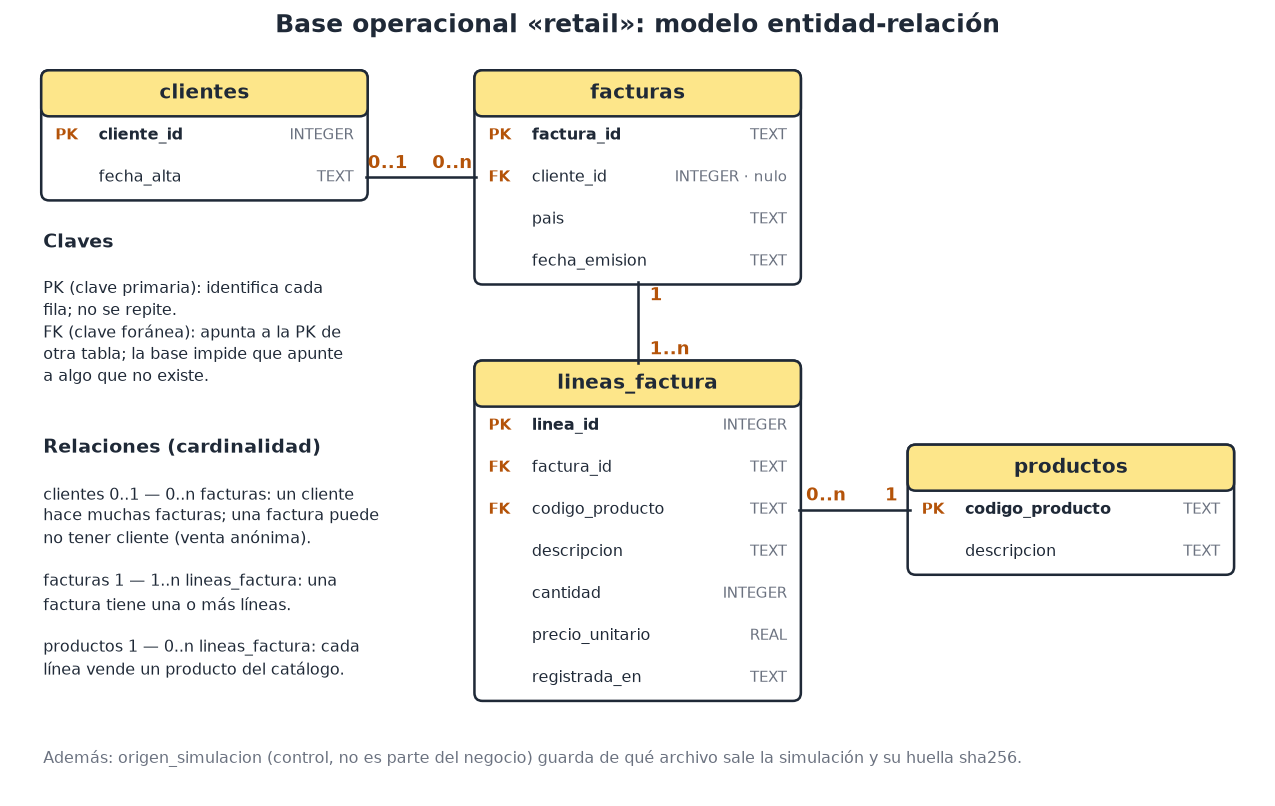

**Cómo leer un modelo entidad-relación (E-R).** Cada caja es una tabla; cada línea, una relación entre dos tablas. Los números indican la
**cardinalidad**: cuántas filas de una tabla pueden relacionarse con una fila de la otra (`1..n` = una o más; `0..1` = ninguna o una).
- **PK (clave primaria):** la columna que identifica cada fila. No se repite ni puede faltar.
- **FK (clave foránea):** una columna que apunta a la PK de otra tabla. La base **impide** guardar una línea de una factura que no existe.
- **NOT NULL:** el campo es obligatorio. Por ejemplo, toda línea tiene cantidad y precio, aunque el precio sea 0.

| Dato del archivo | Dónde queda | Por qué |
|---|---|---|
| `Customer ID`, `Country` | `facturas` | Son de la factura: uno por factura (comprobado en el paso 2) |
| `InvoiceDate` | `lineas_factura.registrada_en` (y la primera en `facturas.fecha_emision`) | Varía dentro de algunas facturas |
| `Description` | `lineas_factura.descripcion` (y la más usada, en `productos`) | El texto de la venta puede diferir del catálogo |
| `StockCode`, `Quantity`, `Price` | `lineas_factura` | Son de la línea |
| (derivado) | `clientes.fecha_alta` | La primera compra registrada del cliente |

In [6]:
ejecutar_script('operacional/02_poblar_operacional.sql')
# Registro de control: de qué archivo, con qué huella y cuántas líneas se construyó esta simulación.
con.execute('INSERT INTO origen_simulacion (fuente, archivo, sha256, filas, creada_en) VALUES (?,?,?,?,?)',
            (FUENTE, ruta.name, sha256_archivo(ruta), len(lineas), datetime.now().isoformat(timespec='seconds')))
con.execute('DROP TABLE temp.tmp_origen')
con.commit()
for tabla in ('clientes', 'productos', 'facturas', 'lineas_factura'):
    print(f'{tabla:15s} {escalar(f"SELECT COUNT(*) FROM {tabla}"):>10,} filas')

clientes               150 filas
productos            3,080 filas
facturas             1,430 filas
lineas_factura      23,070 filas


## 4. Comprobar la simulación
Un pipeline no se da por bueno porque «no dio error»: se **comprueba**. Dos comprobaciones:
1. **Integridad referencial:** `PRAGMA foreign_key_check` lista las filas cuya clave foránea apunta a algo inexistente. Debe estar vacío.
2. **Sin pérdida:** al unir cada línea con su factura debe salir **exactamente** el número de filas del archivo.

Después medimos la suciedad que **sigue ahí**: es justo lo que recibirá RAW y tratará MASTER.

In [7]:
assert con.execute('PRAGMA foreign_key_check').fetchall() == [], 'Hay claves foráneas rotas'
assert escalar('SELECT COUNT(*) FROM lineas_factura l JOIN facturas f ON f.factura_id = l.factura_id') == len(lineas)

pd.DataFrame({'filas': {
    'líneas': escalar('SELECT COUNT(*) FROM lineas_factura'),
    'líneas de cancelaciones (C…)': escalar("SELECT COUNT(*) FROM lineas_factura WHERE factura_id LIKE 'C%'"),
    'líneas de facturas sin cliente': escalar('SELECT COUNT(*) FROM lineas_factura l JOIN facturas f ON f.factura_id = l.factura_id '
                                              'WHERE f.cliente_id IS NULL'),
    'líneas sin descripción': escalar('SELECT COUNT(*) FROM lineas_factura WHERE descripcion IS NULL'),
    'líneas con precio <= 0': escalar('SELECT COUNT(*) FROM lineas_factura WHERE precio_unitario <= 0'),
}})

,filas
líneas,23070
líneas de cancelaciones (C…),404
líneas de facturas sin cliente,300
líneas sin descripción,6
líneas con precio <= 0,7


Así ve el sistema de ventas una factura: la **cabecera** (`facturas`), sus **líneas** (`lineas_factura`) y el **catálogo** (`productos`),
unidos por sus claves con `JOIN`. Fíjate en que el cliente y el país aparecen una sola vez por factura en la base, aunque aquí se repitan al unir.

In [8]:
pd.read_sql("""
    SELECT f.factura_id, f.fecha_emision, f.cliente_id, f.pais, l.linea_id, l.codigo_producto, p.descripcion AS en_catalogo,
           l.cantidad, l.precio_unitario
    FROM facturas f
    JOIN lineas_factura l ON l.factura_id = f.factura_id
    JOIN productos p ON p.codigo_producto = l.codigo_producto
    WHERE f.factura_id = (SELECT MIN(factura_id) FROM facturas WHERE cliente_id IS NOT NULL)
    ORDER BY l.linea_id LIMIT 8""", con)

,factura_id,fecha_emision,cliente_id,pais,linea_id,codigo_producto,en_catalogo,cantidad,precio_unitario
0,489547,2009-12-01 12:30:00,13599,United Kingdom,2,22086,PAPER CHAIN KIT 50'S CHRISTMAS,18,2.95
1,489547,2009-12-01 12:30:00,13599,United Kingdom,3,21871,SAVE THE PLANET MUG,12,1.25
2,489547,2009-12-01 12:30:00,13599,United Kingdom,4,21875,KINGS CHOICE MUG,12,1.25
3,489547,2009-12-01 12:30:00,13599,United Kingdom,5,21587,COSY HOUR GIANT TUBE MATCHES,12,2.55
4,489547,2009-12-01 12:30:00,13599,United Kingdom,6,21593,SWALLOW CIGAR BOX MATCHES,24,1.25
5,489547,2009-12-01 12:30:00,13599,United Kingdom,7,21591,COSY HOUR CIGAR BOX MATCHES,24,1.25
6,489547,2009-12-01 12:30:00,13599,United Kingdom,8,21590,KINGS CHOICE CIGAR BOX MATCHES,24,1.25
7,489547,2009-12-01 12:30:00,13599,United Kingdom,9,22083,PAPER CHAIN KIT RETROSPOT,6,2.95


In [9]:
con.close()
print('Listo: base operacional en', DB_OPERACIONAL)

Listo: base operacional en C:\bk\HC-Cursos\curso-ml-ia-desarrollo-produccion\04-Proyecto-Base\data\external\retail.db


## Resumen
- Hemos construido `retail.db`, el **sistema operacional simulado**: 4 tablas normalizadas, con claves y restricciones.
- Antes de normalizar **medimos** que no se perdía información; después **comprobamos** las claves foráneas y que se reconstruyen todas las líneas.
- La suciedad del origen **sigue ahí** a propósito.

**Siguiente:** el cuaderno **01** copia estas tablas a la capa RAW de la base analítica (la *ingesta*) y las depura en MASTER.

## Para practicar
1. Busca una factura con líneas en fechas distintas. ¿Qué fecha guarda `facturas.fecha_emision` y por qué cada línea conserva la suya?
2. ¿Por qué `productos.descripcion` y `lineas_factura.descripcion` pueden no coincidir? ¿Cuál de las dos describe la venta?
3. Intenta insertar a mano una línea de una factura que no existe (`INSERT INTO lineas_factura …`). ¿Qué hace la base y por qué?
4. Explica en dos frases por qué el pipeline analítico no debe escribir en esta base.